# Frozen reference-selection evaluation

Chemical baseline, Euclidean/cosine kNN, and GCN/GAT/GraphSAGE on physical/cosine graphs.
Each method ranks the same fixed held-out batches of 600. No JEPA inference is required.

**Part I** generates scores and the union to evaluate. **Part II** runs on SoC.
**Part III** resumes here after receiving candidate and fixed-phase predictions.
The models remain frozen; the reserved population was evaluated in earlier work.

Main entry point: this repository-root notebook. Notebook helpers live in `utils/eval/evaluation/`; inputs and outputs live in `data/eval/`. Run from the Crys_METH repository root with the existing **crys_meth** Conda environment.


In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data/eval/config.json').is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
EVALUATION_UTILS = ROOT / 'utils/eval'
if str(EVALUATION_UTILS) not in sys.path:
    sys.path.insert(0, str(EVALUATION_UTILS))
import numpy as np
import pandas as pd
from evaluation.common import load_config, verify, read_json, input_files
from evaluation.inference.graphs import verify_graphs, load_graph
from evaluation.inputs import audit, load_structures
from evaluation.scoring import generate_scores
from evaluation.selection import export_selections, make_selections
from evaluation.proxies import calculate_hulls
from evaluation.analysis import analyse
c = load_config(ROOT / 'data/eval/config.json')


## 1. Check original inputs and saved splits

These indices address rows of the supplied original candidate vectors. We verify
source hashes, metadata order, and disjoint fit/validation/reserved chemical systems.
The old manifest calls reserved rows `train` because the reserve split was created later.

Inputs are organised under `data/eval/inputs/candidates/`, `references/`, and
`splits/`. The next section rebuilds the original reference graphs from those
inputs. Historical training/completion records are optional verification evidence;
missing records are logged, while the saved model metadata is used for inference.


In [2]:
audit_result = audit(c)
print({k: audit_result[k] for k in ['candidate_count', 'reference_count', 'split_counts', 'ready_for_gnn']})
for missing in audit_result['blockers']:
    print(missing)

print(f"Historical provenance notes: {len(audit_result['provenance_notes'])}")
display(pd.DataFrame([{'input': name, 'path': str(path.relative_to(ROOT))} for name, path in input_files(c).items()]))


{'candidate_count': 324622, 'reference_count': 27136, 'split_counts': {'train': 141126, 'validation': 37438, 'reserved': 35332}, 'ready_for_gnn': True}
Historical provenance notes: 23


,input,path
0,candidate_embeddings.npy,data/eval/inputs/candidates/candidate_em...
1,candidate_metadata.csv,data/eval/inputs/candidates/candidate_me...
2,candidate_decompositions.csv,data/eval/inputs/candidates/candidate_de...
3,embeddings.npy,data/eval/inputs/references/embeddings.npy
4,metadata.csv,data/eval/inputs/references/metadata.csv
5,split_manifest.csv,data/eval/inputs/splits/split_manifest.csv
6,split_protocol.json,data/eval/inputs/splits/split_protocol.json
7,train_rows.npy,data/eval/inputs/splits/train_rows.npy
8,validation_rows.npy,data/eval/inputs/splits/validation_rows.npy
9,reserved_rows.npy,data/eval/inputs/splits/reserved_rows.npy


## 1b. Load the reference graphs constructed on SoC

Graph construction runs on SoC, using `utils/eval/evaluation/inference/graphs.py`
module. The notebook only verifies and loads the completed graph outputs.

After uploading the source overlay and the original data, submit from
**cluster xlogin Bash**:
```bash
cd ~/Crys_METH
sbatch utils/eval/evaluation/cluster/run_cpu.sh graphs --config data/eval/cluster_config.json
```

After the job succeeds, download `data/eval/graphs/` into the same
local path, replacing any older local graph outputs. See README for transfer and
job-status commands. Run the next cell only after that download completes.

The physical graph uses fit decompositions only; validation and reserved rows are
excluded. The cosine graph follows the original float64 reference-neighbour
retrieval, symmetric-max weights, and unit self-loops. `graph_build.json` records
source/input hashes and graph statistics. Historical graph checksums are unavailable,
so reconstruction is recorded without claiming independently certified byte identity.


In [3]:
# Download the completed graph folder from SoC before continuing.
graph_record = verify_graphs(c)
print({key: graph_record[key] for key in ['reference_count', 'fit_rows', 'validation_rows_excluded', 'reserved_rows_excluded', 'cooccurrence_pair_count']})
for name in ('physical', 'cosine'):
    graph = load_graph(c, name)
    print(name, graph.shape, 'stored edges including loops:', graph.nnz)
audit_result = audit(c)
print('Ready for GNN inference:', audit_result['ready_for_gnn'])


{'reference_count': 27136, 'fit_rows': 141126, 'validation_rows_excluded': 37438, 'reserved_rows_excluded': 35332, 'cooccurrence_pair_count': 25943}
physical (27136, 27136) stored edges including loops: 79022
cosine (27136, 27136) stored edges including loops: 429656
Ready for GNN inference: True


## 2. Load the prepared SoC structures and batch membership

Download `candidates.csv`, `structures.sqlite`, and `structures_complete.json`
after the SoC structures job has finished. The next cell verifies and loads that
bundle; it never tries to read the original release JSONs on the laptop.

If the completion receipt is missing, download it before continuing, even when
the CSV and database are already present. See README's remote structure step.
Seed 2026 determines the saved shuffle; final-batch budgets use floor rounding.


In [4]:
candidates = load_structures(c)
display(candidates[['candidate_row', 'eval_folder', 'idx', 'batch', 'batch_position', 'formula']].head())
display(candidates.groupby('batch').size().rename('population').to_frame().tail())


,candidate_row,eval_folder,idx,batch,batch_position,formula
0,167440,206,391,0,0,Tb4Bi3Pb
1,34908,42,574,0,1,ErAl12
2,38385,46,815,0,2,ScZnPb
3,319958,394,224,0,3,Sr2Gd2MnCuO8
4,315879,389,226,0,4,ThB2Ru2Rh


,population
batch,
54,600
55,600
56,600
57,600
58,532


## 3. Generate all method scores

All methods use the supplied 27,136-reference JEPA bank. Chemical scoring uses
mean squared distance over chemically eligible references. Euclidean kNN uses
mean squared Euclidean distance; cosine kNN uses mean cosine distance. Both use
k = 5, 10, 15, 25. The primary neighbour count is 5.

The frozen GNNs retain their original features, formula prior, and chemical-union-
cosine-5 candidate-reference pool. The graph topology is a separate setting.
Three seeds are scored individually for every architecture and graph, with
no-graph and random-candidate controls. Lower scores rank first.

This cell loads the original GNN classes/checkpoints through shared Python
functions. It reads no stability labels or decomposition targets.

Graphs are loaded through the same reusable graph module used in construction.


In [5]:
scores = generate_scores(c)
methods = read_json(c['output'] / 'score_manifest.json')['methods']
print(f'{len(methods)} methods; {len(scores):,} held-out candidates')
display(scores[['candidate_row', 'chemical', 'knn_euclidean_5', 'knn_cosine_5']].head())


31 methods; 35,332 held-out candidates


,candidate_row,chemical,knn_euclidean_5,knn_cosine_5
0,167440,156.20626570295963,0.222766,0.001398
1,34908,126.26072567234918,0.149047,0.000950
2,38385,117.21999895187531,0.352266,0.002384
3,319958,158.95707131827209,0.054434,0.000346
4,315879,141.39367198830627,3.549094,0.022650


## 4. Rank, select top 1/5/7%, and freeze the union

Within each batch, skip StructureMatcher duplicates and refill from the same
ranking. Full 600-candidate batches receive 6, 30, and 42 requested slots.
Also retain raw selections as a secondary analysis. Ties use original row IDs.
Export the union over methods, seeds, policies, and budgets once for both proxies.
Repeated structures are predicted once through structure-addressed caching.


In [6]:
workload = export_selections(c)
display(workload)
display(pd.read_csv(c['output'] / 'selection_requests.csv').head())


{'heldout_candidates': 35332,
 'selected_union': 10939,
 'methods': 31,
 'fractions': [0.01, 0.05, 0.07],
 'phase_predictions': 'Additional; determined by all eligible chemical systems',
 'policies': ['raw', 'unique_refill']}

,batch,method,policy,fraction,population,budget,selected_count,unfilled_count,scoreable_count
0,0,chemical,raw,0.01,600,6,6,0,600
1,0,chemical,raw,0.05,600,30,30,0,600
2,0,chemical,raw,0.07,600,42,42,0,600
3,0,chemical,unique_refill,0.01,600,6,6,0,600
4,0,chemical,unique_refill,0.05,600,30,30,0,600


## 5. Handoff: run energy inference on SoC

**Stop local execution here until SoC inference has finished.** MEGNet and CHGNet
require their own model environments and substantial candidate/reference inference.
SoC provides the GPU and the existing MP2023 phase database; the laptop performs
ranking and analysis using cached embeddings.

1. Review/upload the source overlay using `PYTHONPATH=utils/eval python -m evaluation.bundle` and README.
2. Upload the frozen files listed in `selection_complete.json`, plus that receipt.
3. Set the observed release, phase-database, output, cache, and model paths in
   `data/eval/cluster_config.json`. Reuse the existing MEGNet environment.
4. Prepare all relevant fixed MP2023 phases; install CHGNet only in an allocation.
5. Run the real-weight smoke tests, then submit each proxy's prediction stage.
6. Check job exit status, pending counts, and failed-prediction records.
7. Export the consistent SQLite/result snapshot and download its `returned/` folder.

**Cluster xlogin Bash** (after upload/configuration; wait for each prerequisite):
```bash
sbatch utils/eval/evaluation/cluster/run_cpu.sh phases --config data/eval/cluster_config.json
sbatch utils/eval/evaluation/cluster/run_gpu.sh smoke megnet --config data/eval/cluster_config.json
sbatch utils/eval/evaluation/cluster/run_gpu.sh smoke chgnet --config data/eval/cluster_config.json
# After both smoke jobs pass:
sbatch utils/eval/evaluation/cluster/run_gpu.sh predict megnet --config data/eval/cluster_config.json
sbatch utils/eval/evaluation/cluster/run_gpu.sh predict chgnet --config data/eval/cluster_config.json
# After both prediction jobs finish:
sbatch utils/eval/evaluation/cluster/run_cpu.sh export --config data/eval/cluster_config.json
```

See README for setup, transfers, preflight, logging, and timeout recovery. No
cluster commands are executed by this notebook. Predictions are single-point
energies on the saved geometries; no new relaxation is performed.


## 6. Resume after receiving the phase and candidate predictions

From this cell onward, the completed `returned/` bundle is required. It contains
MEGNet/CHGNet candidate energies, reference-phase energies, structures, and receipts.
The atomistic models are not loaded locally. Check every transferred checksum
before calculating hull labels or making plots.


In [7]:
RETURNED_READY = True  # Set True only after the completed bundle has been downloaded.
if not RETURNED_READY:
    raise RuntimeError('Complete the SoC handoff above, then set RETURNED_READY = True.')
returned = c['output'] / 'returned'
verify(returned, 'transfer_complete.json')
analysis_config = dict(c, output=returned)
verify(returned, 'selection_complete.json')
# Reproduce selections with the same functions and frozen score/duplicate tables.
frozen_scores = pd.read_csv(returned / 'scores.csv')
pairs = pd.read_csv(returned / 'duplicate_pairs.csv')[['a', 'b']].to_numpy().tolist()
manifest = read_json(returned / 'selection_complete.json')
reselected, rerequests = make_selections(frozen_scores, manifest['methods'], manifest['fractions'], pairs)
pd.testing.assert_frame_equal(reselected, pd.read_csv(returned / 'selections.csv'), check_dtype=False)
pd.testing.assert_frame_equal(rerequests, pd.read_csv(returned / 'selection_requests.csv'), check_dtype=False)
print('Transfer checks and selection reproduction passed.')


Transfer checks and selection reproduction passed.


## 7. Common energy-above-hull calculation

Compute a separate fixed hull for each proxy. MEGNet supplies formation energy
per atom; CHGNet supplies total energy per atom. Each candidate is compared with
phase energies from that same proxy. Elemental-reference terms cancel at a fixed
composition. Generated candidates are never added to the hull.

Primary pass: signed energy above hull **< 0.1 eV/atom**. Secondary thresholds:
<0.05 and <=0. Failed predictions or incomplete phase banks stay unknown.


In [8]:
labels = {proxy: calculate_hulls(analysis_config, proxy) for proxy in ('megnet', 'chgnet')}
for proxy, frame in labels.items():
    print(proxy, frame.hull_status.value_counts().to_dict())


megnet {'ok': 10939}
chgnet {'ok': 10120, 'incomplete_reference_hull': 819}


## 8. Stability, union discoveries, and comparisons

**Yield:** confirmed stable / requested slots. **Precision:** stable / valid labels.
Report unknown-label coverage and upper/lower yield bounds separately.

**Discovery share:** stable selections / stable discoveries in the evaluated union
at the same budget and duplicate policy. This is not full-population recall and
method shares can overlap. Three seeds remain separate observations of trained
models; their range is not a confidence interval. Paired chemical-system bootstrap
intervals are descriptive and use fixed selections, with unknowns unconfirmed.


In [9]:
# Reuse the completed aggregate analysis; focused 1% figures follow below.
if (returned / 'analysis_complete.json').is_file():
    verify(returned, 'analysis_complete.json')
    batch_metrics = pd.read_csv(returned / 'batch_metrics.csv')
    summary = pd.read_csv(returned / 'aggregate_metrics.csv')
else:
    batch_metrics, summary = analyse(analysis_config)
print('Full-budget metrics loaded. The following section shows only the 1% budget.')


Full-budget metrics loaded. The following section shows only the 1% budget.


## 8a. Focus on the 1% budget

This section compares **only top-1% unique-refill selections**, using the strict
proxy hull-distance threshold **< 0.1 eV/atom**. Each method has **353 requested
slots** across the 59 batches: 58 full batches select 6 candidates each and the
last batch selects 5.

We rank method families **separately under MEGNet and CHGNet**, then plot only the
**five best alternatives plus chemical**. GNN architecture/graph combinations are
summarized by the mean of their three seed-specific results; we do not choose the
best seed or create a score ensemble. When yields tie at the cutoff, smaller k,
then method ID, decides display order only.

The main metric is **confirmed stable / requested slots**, keeping unknown labels
in the denominator. Hatched extensions show the optimistic result if all unknowns
pass; these bounds are not confidence intervals. Paired chemical-system bootstrap
intervals use 2,000 draws and preserve dependence between GNN seeds. They are
unadjusted descriptive intervals, and the top-five choice is exploratory.

The code below rechecks counts against the selected IDs and labels. It does not
rerun proxy inference, model training, scoring, or candidate selection.


In [10]:
from evaluation.focus_one_percent import analyse_one_percent
from IPython.display import display, Image, Markdown
focus_1pct = analyse_one_percent(analysis_config, top_n=5)
display(focus_1pct['coverage'])


,proxy,phase_predictions,failed_phase_predictions,candidate_union,valid_hull_labels,unknown_hull_labels
0,megnet,78066,0,10939,10939,0
1,chgnet,78066,107,10939,10120,819


## 8b. Top five alternatives plus chemical: stability yield

Left: confirmed stable selections per requested slot. The labels show stable
counts out of 353; for GNNs the bar is the three-seed mean and black dots are the
individual seed results. Right: gain versus chemical, with descriptive 95%
chemical-system bootstrap intervals. An interval crossing zero does not establish
an advantage or equivalence.


### MEGNET ? 1% budget

,Method,Runs,Stable (seed mean for GNN),Requested slots,Confirmed yield (%),Unknown (seed mean for GNN),Gain vs chemical (pp),Descriptive 95% interval (pp)
0,Chemical baseline,1,261.0,353,73.94,0.0,0.00,"[0.00, 0.00]"
1,"kNN cosine, k=15",1,282.0,353,79.89,0.0,5.95,"[-4.56, 20.87]"
2,"kNN euclidean, k=15",1,281.0,353,79.60,0.0,5.67,"[-4.88, 20.25]"
3,"kNN cosine, k=5",1,279.0,353,79.04,0.0,5.10,"[-5.65, 19.88]"
4,"kNN euclidean, k=5",1,279.0,353,79.04,0.0,5.10,"[-5.52, 19.70]"
5,"kNN cosine, k=10",1,279.0,353,79.04,0.0,5.10,"[-5.20, 20.01]"


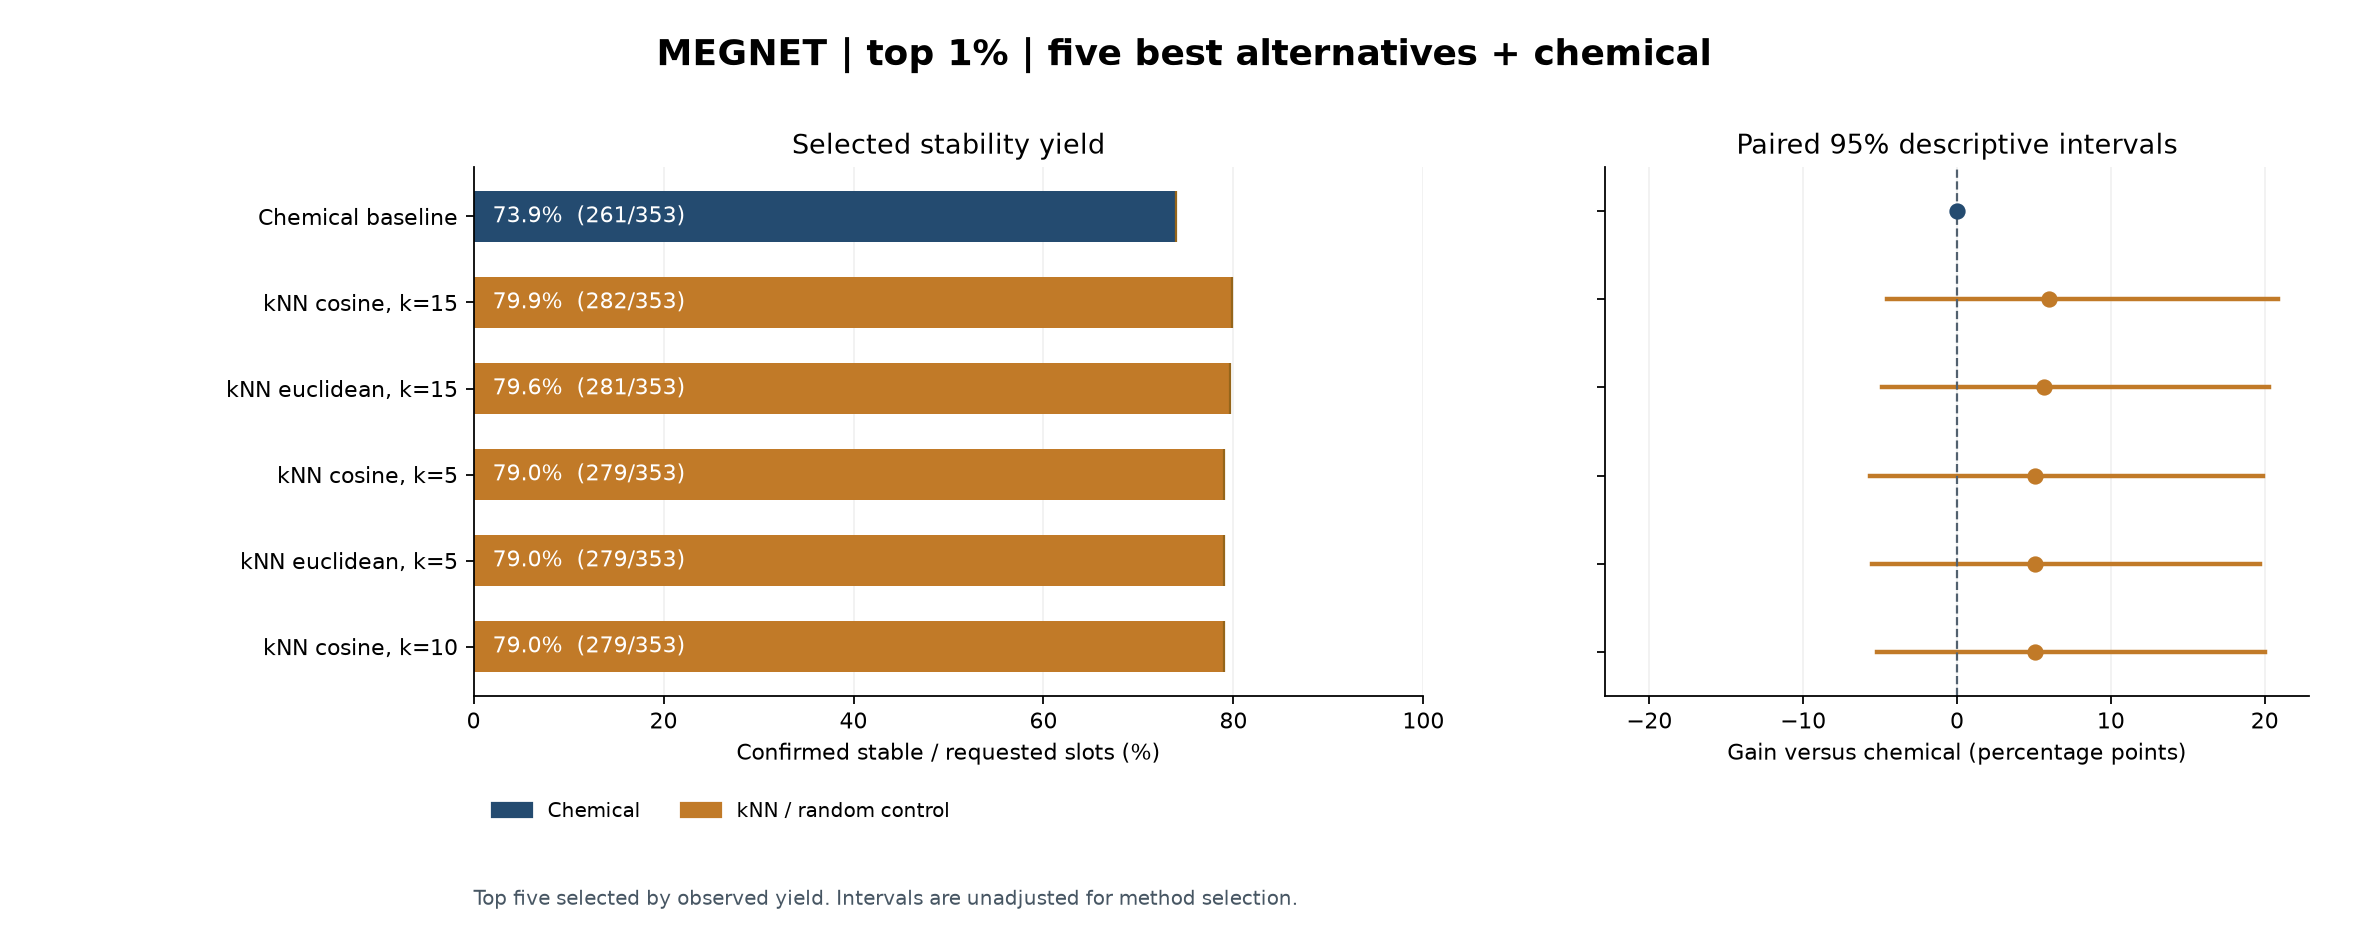

### CHGNET ? 1% budget

,Method,Runs,Stable (seed mean for GNN),Requested slots,Confirmed yield (%),Unknown (seed mean for GNN),Gain vs chemical (pp),Descriptive 95% interval (pp)
0,Chemical baseline,1,302.00,353,85.55,8.00,0.00,"[0.00, 0.00]"
1,"kNN euclidean, k=10",1,274.00,353,77.62,8.00,-7.93,"[-15.18, 2.44]"
2,"kNN cosine, k=5",1,273.00,353,77.34,6.00,-8.22,"[-15.68, 1.86]"
3,"kNN euclidean, k=5",1,272.00,353,77.05,6.00,-8.50,"[-15.93, 1.81]"
4,"kNN cosine, k=10",1,271.00,353,76.77,8.00,-8.78,"[-16.38, 1.81]"
5,GraphSAGE / physical,3,269.67,353,76.39,17.33,-9.16,"[-16.67, 0.20]"


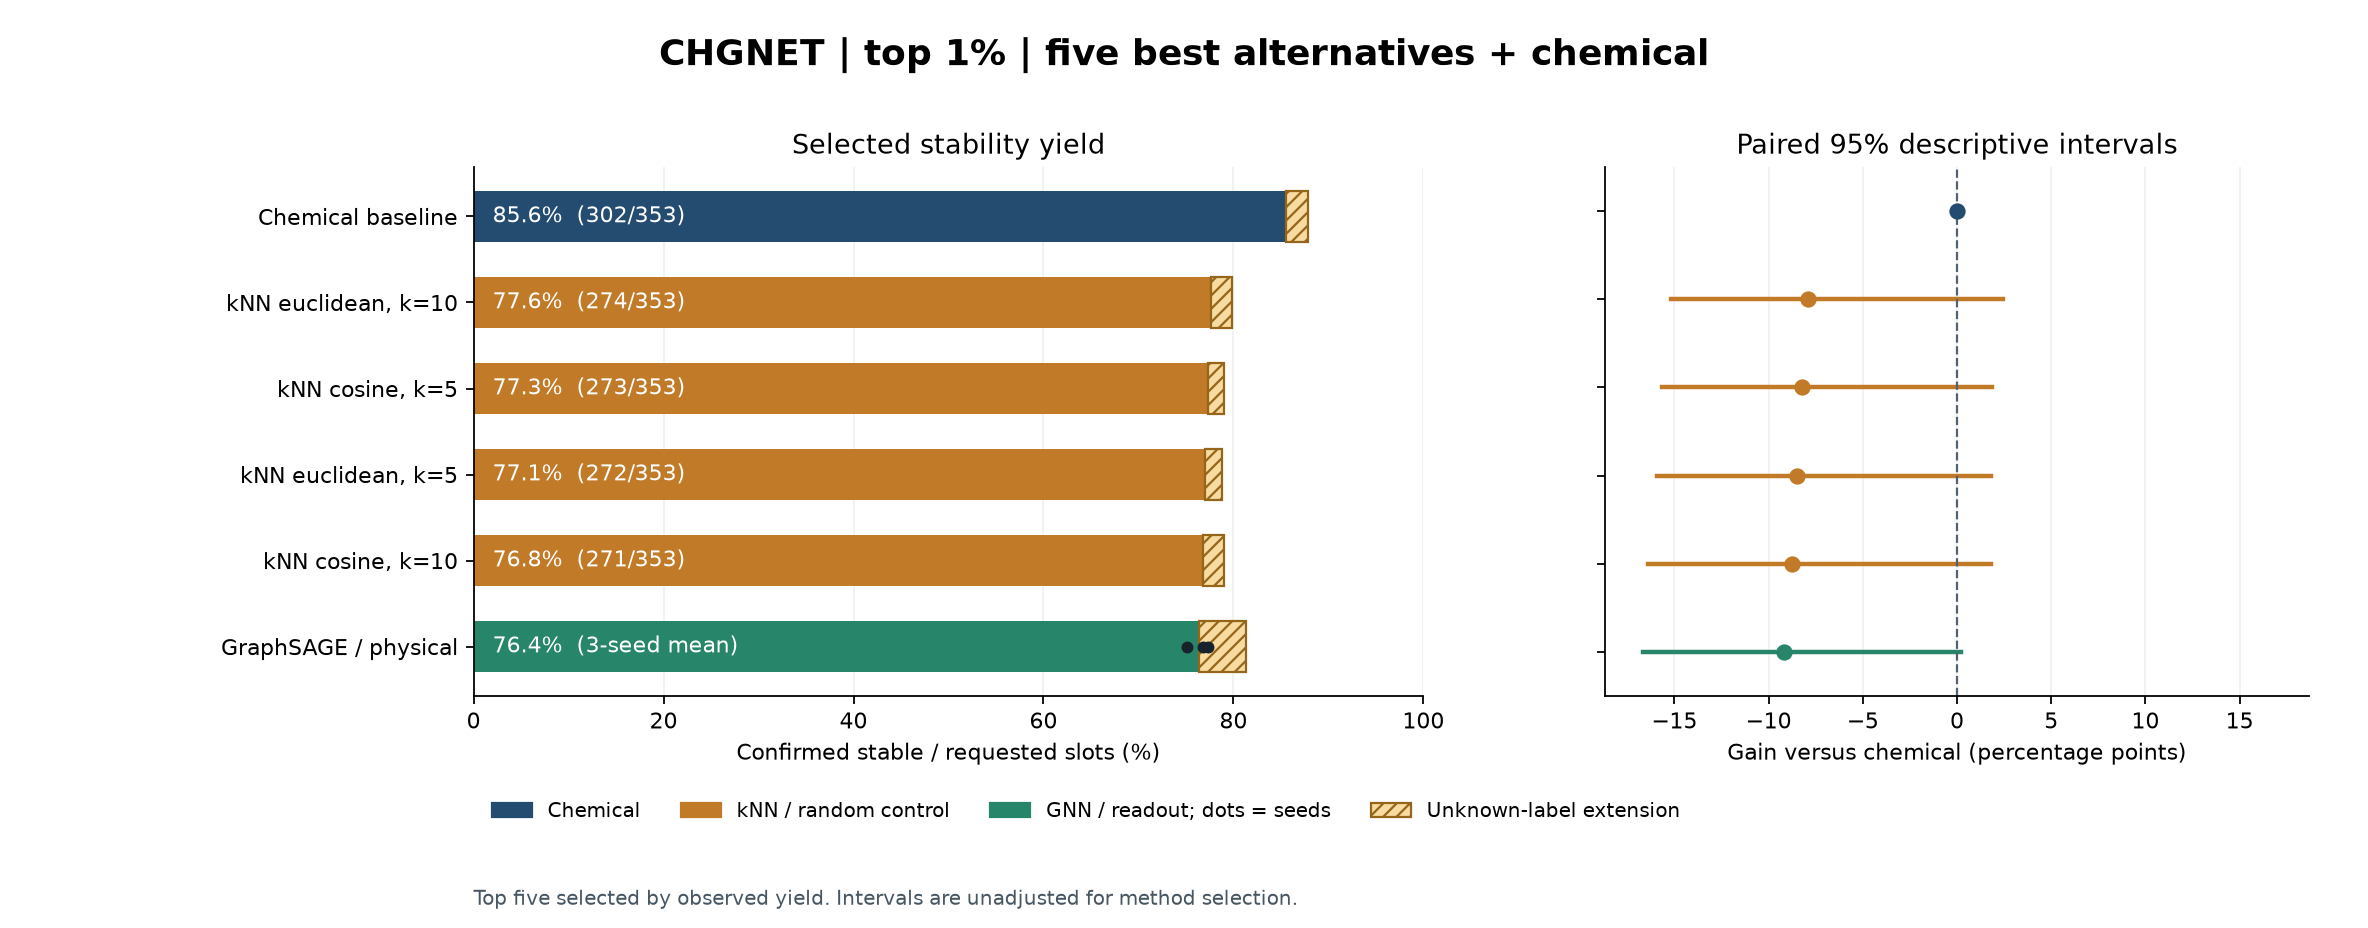

In [11]:
for proxy in ('megnet', 'chgnet'):
    view = focus_1pct['top'].query('proxy == @proxy').sort_values('display_rank')
    compact = pd.DataFrame({
        'Method': view.label,
        'Runs': view.n_runs,
        'Stable (seed mean for GNN)': view.stable_mean.round(2),
        'Requested slots': view.requested_slots,
        'Confirmed yield (%)': (100 * view.yield_mean).round(2),
        'Unknown (seed mean for GNN)': view.unknown_mean.round(2),
        'Gain vs chemical (pp)': (100 * view.gain_vs_chemical).round(2),
        'Descriptive 95% interval (pp)': [f'[{100*a:.2f}, {100*b:.2f}]' for a,b in zip(view.ci_low, view.ci_high)],
    }).reset_index(drop=True)
    display(Markdown(f'### {proxy.upper()} ? 1% budget'))
    display(compact)
    display(Image(filename=str(focus_1pct['directory'] / f'{proxy}_top5_1pct.png'), width=1200))


## 8c. The same six methods, batch by batch

Each panel contains only one method and the chemical reference. Faint dots are
per-batch yields; solid lines use totals over a rolling five-batch window, compared
with chemical's dashed line. At a 1% budget there are only 5?6 picks per batch, so
individual batch percentages are coarse. Batch order is a saved random shuffle,
not a chronological learning curve. GNN values are seed means.


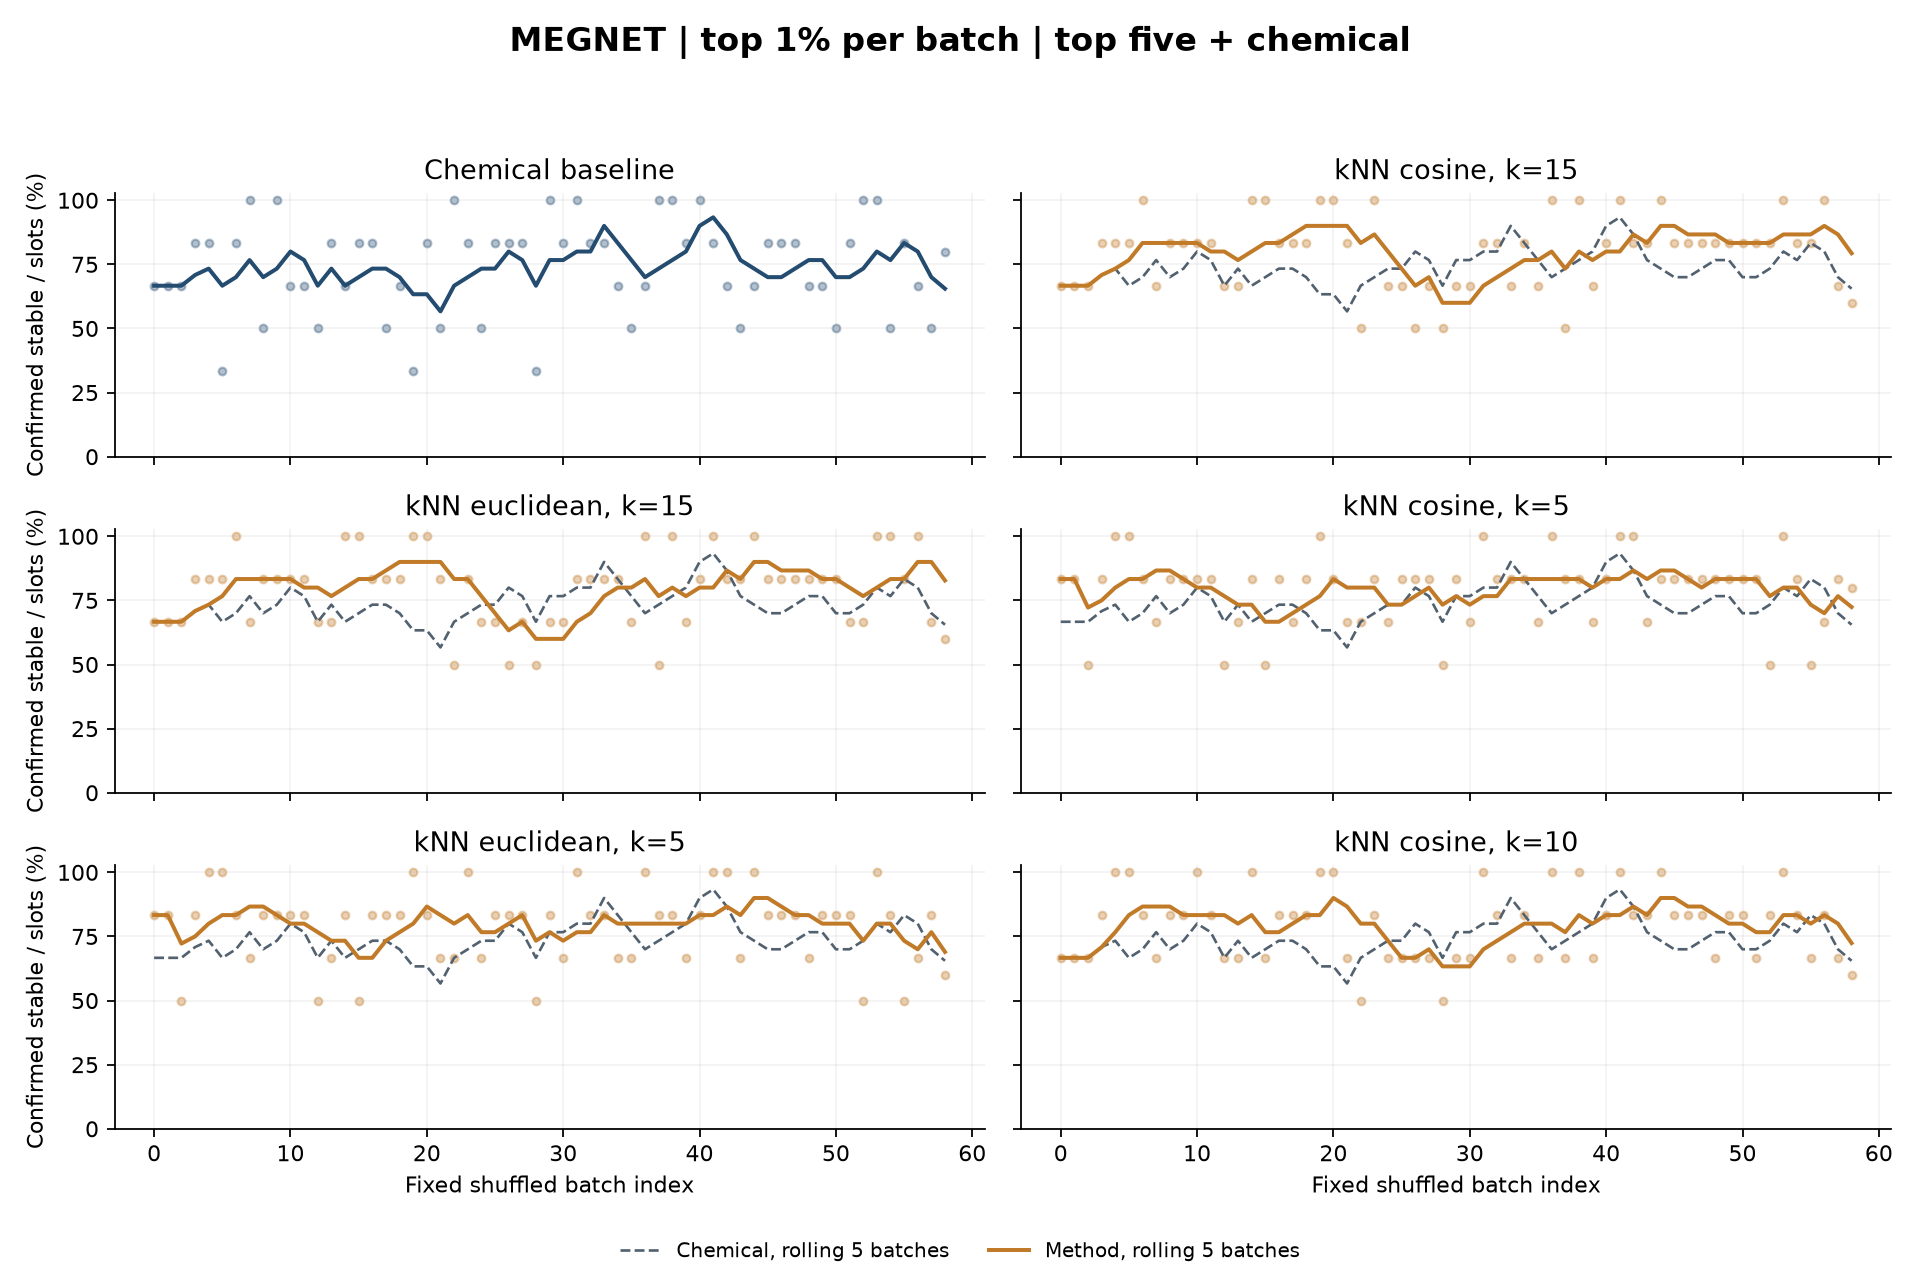

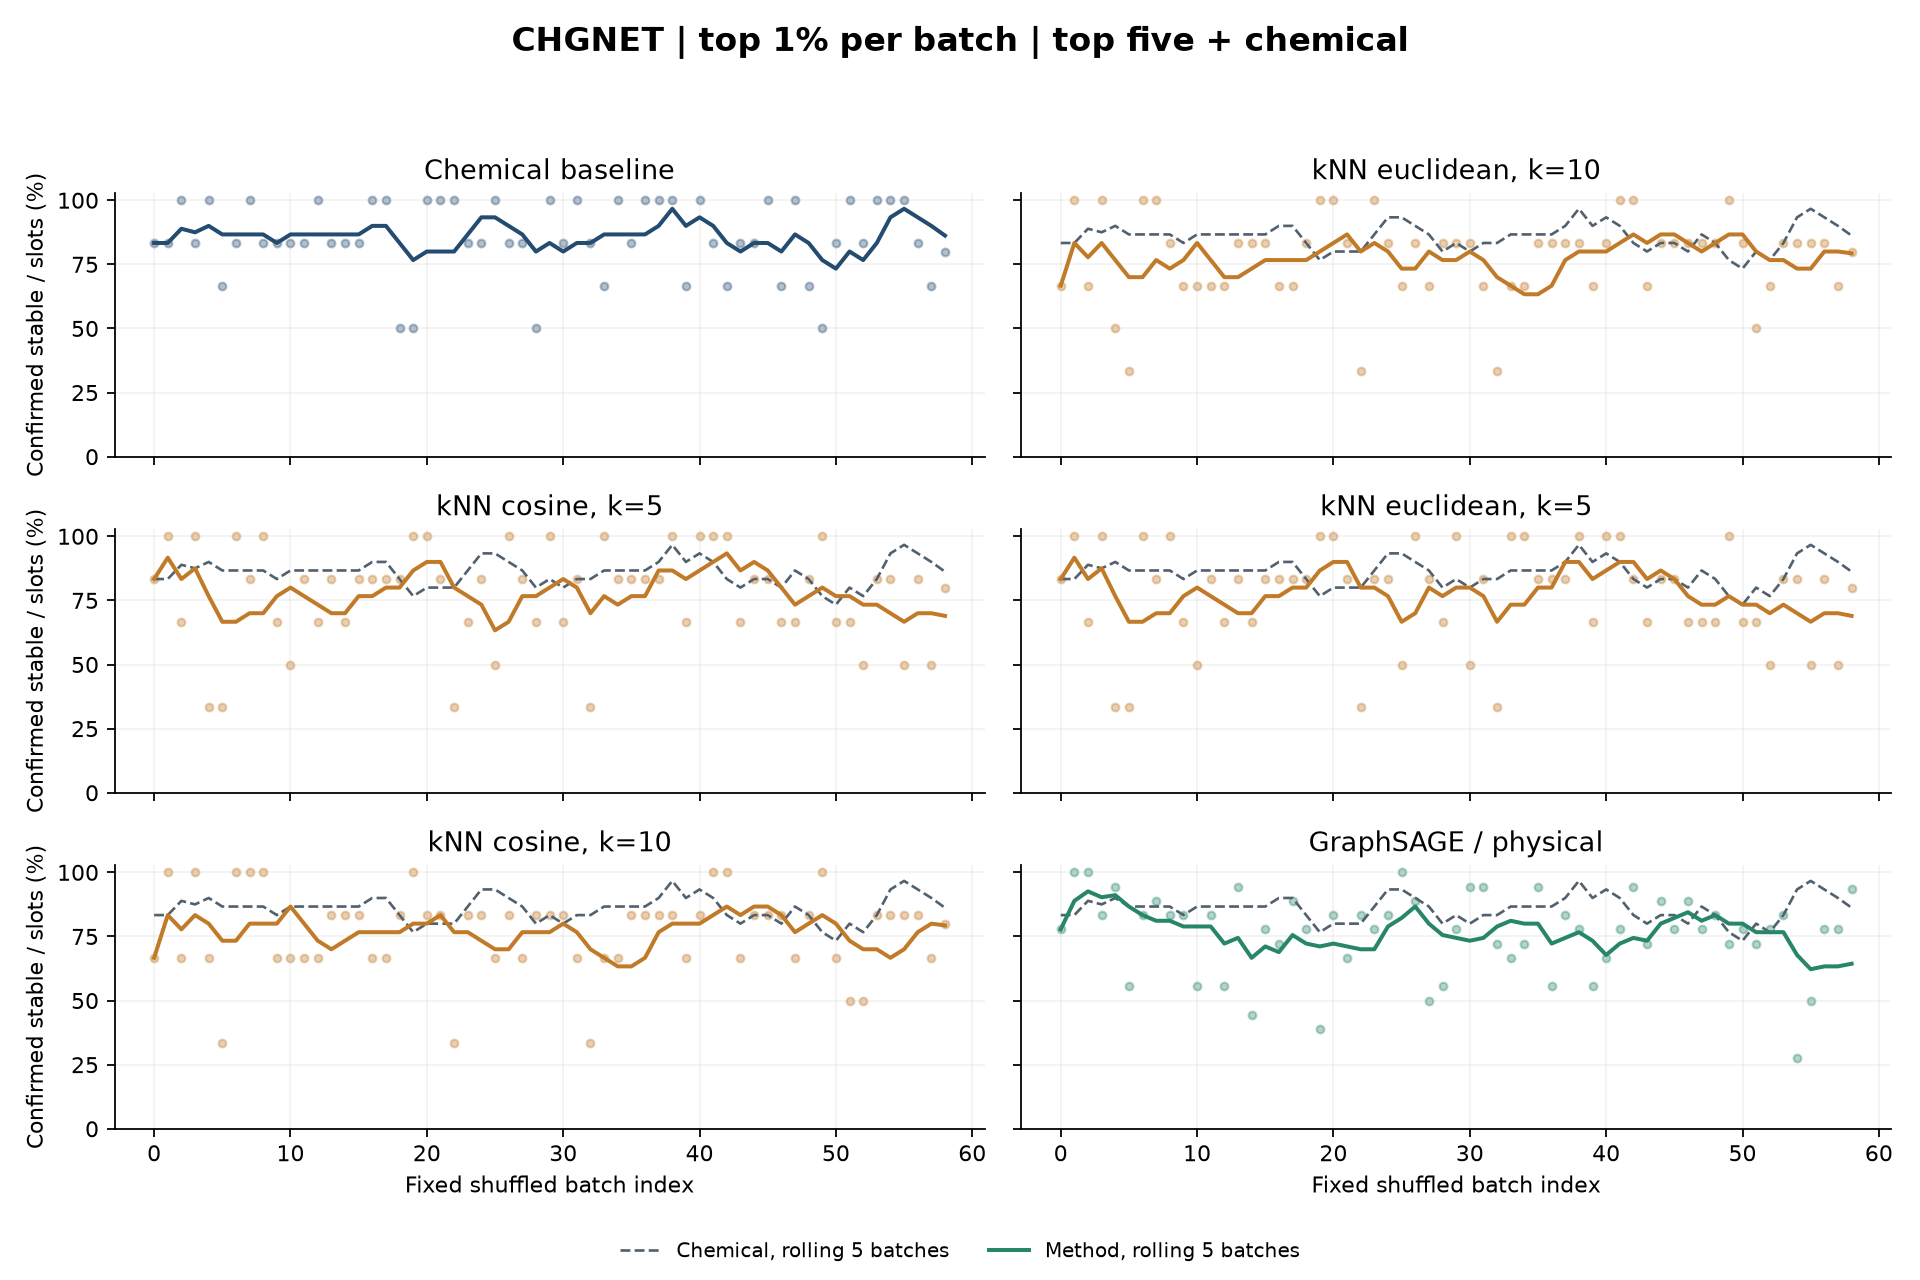

In [12]:
for proxy in ('megnet', 'chgnet'):
    display(Image(filename=str(focus_1pct['directory'] / f'{proxy}_top5_1pct_batches.png'), width=1100))


## 8d. Share of stable discoveries in the evaluated 1% union

The denominator is the number of **confirmed stable candidates in the union of
all methods' 1% unique-refill selections**, not the full 35,332-candidate population
and not the union across all budgets. Selected methods overlap, so the bars need
not sum to 100%. Unknown union labels are reported in each figure.


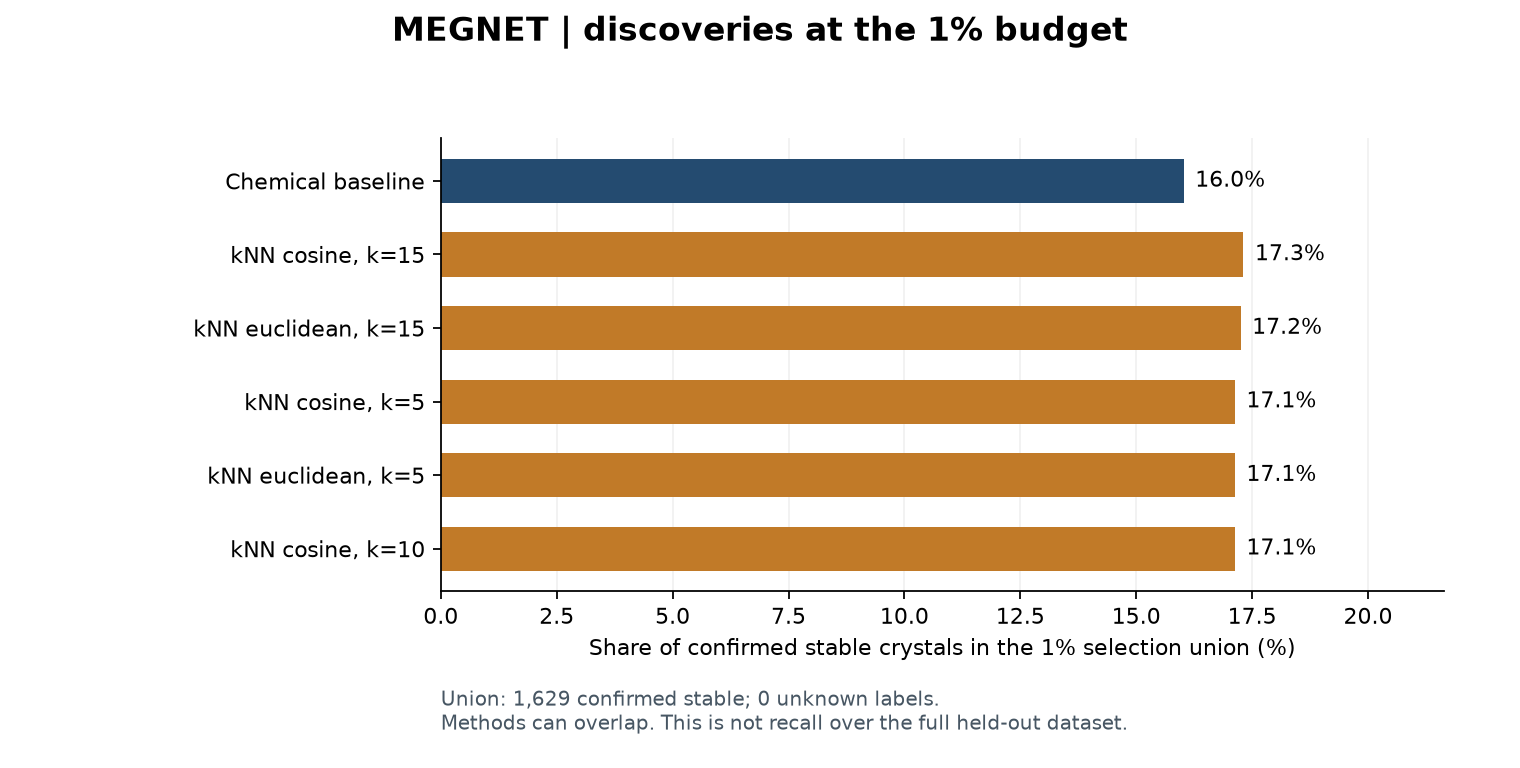

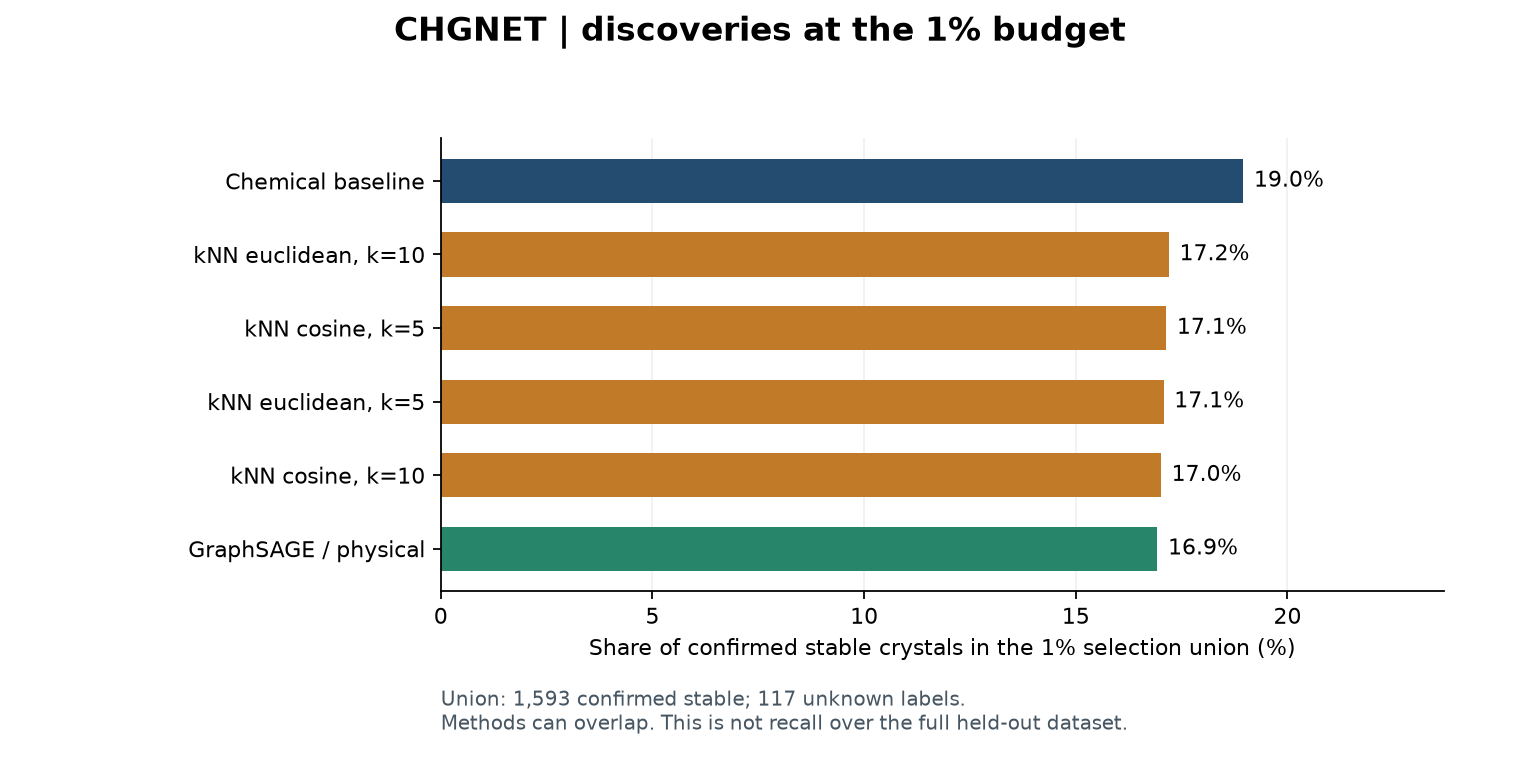

In [13]:
for proxy in ('megnet', 'chgnet'):
    display(Image(filename=str(focus_1pct['directory'] / f'{proxy}_top5_1pct_discoveries.png'), width=950))


## 8e. Is there a clear winner?

The summary below uses all method families, not just the five displayed ones.
It separates observed rankings, seed variation, missing-label sensitivity, and
paired uncertainty. Full family tables and individual seed results are also saved
under `returned/focus_1pct/` for inspection.


In [14]:
display(Markdown(focus_1pct['interpretation']))


### Is there a clear winner at 1%?

The ranking depends on the proxy; these results do not establish one method as best across both evaluators.

- **MEGNET:** numerical leader **kNN cosine, k=15**, 79.9%; chemical gives 261/353 = 73.9%.

  No alternative has a descriptive paired 95% interval wholly above chemical.

  The top-five cutoff has tied methods: kNN cosine, k=10, kNN cosine, k=5, kNN euclidean, k=10, kNN euclidean, k=5. Smaller k, then method ID, breaks display ties; no performance difference is established between ties.

- **CHGNET:** numerical leader **Chemical baseline**, 85.6%; chemical gives 302/353 = 85.6%.

  No alternative has a descriptive paired 95% interval wholly above chemical.

  Chemical remains ahead even if all unknown labels of every alternative pass. This is a missing-label sensitivity result, not a confidence interval.

- Best GNN **by three-seed mean** under CHGNET: GraphSAGE / physical, 76.4%, seed range 75.1% to 77.3%. Seed range is not a confidence interval.

- Best GNN **by three-seed mean** under MEGNET: GraphSAGE / physical, 78.1%, seed range 76.2% to 79.9%. Seed range is not a confidence interval.

- **Coverage:** CHGNET has 819 unknown hull labels in the full evaluated union; 107 phase predictions failed. Unknowns remain visible.

Top-five rankings are exploratory choices from the evaluated data. Intervals are unadjusted for multiple methods; lack of a clear advantage does not establish equivalence. Proxy labels are not DFT confirmation.

## 8f. Presentation view: best observed run per architecture

For reporting, show **GCN, GraphSAGE, and GAT separately**, selecting the best observed run across physical/cosine graphs and the three seeds for each architecture and proxy. Select the best k separately for Euclidean and cosine kNN, and retain the chemical baseline. This gives six categories on each plot.

Selection maximizes confirmed stable selections per requested slot at the 1% budget. Ties prefer fewer unknown labels, then smaller k, then method ID. These are descriptive best-observed results selected using evaluation outcomes; the seed-average and uncertainty analyses above remain the basis for assessing consistency. Seeds are omitted from plot labels and retained in the table and provenance CSV. Slides 17 and 18 use these MEGNet and CHGNet plots respectively.

,proxy,category,method,stable_count,unknown_count,budget,yield_lower
0,chgnet,Chemical baseline,chemical,302,8,353,0.855524
1,chgnet,Euclidean kNN,knn_euclidean_10,274,8,353,0.776204
2,chgnet,Cosine kNN,knn_cosine_5,273,6,353,0.773371
3,chgnet,GCN,gcn_physical_seed2027,271,19,353,0.767705
4,chgnet,GraphSAGE,sage_physical_seed2028,273,13,353,0.773371
5,chgnet,GAT,gat_physical_seed2028,266,10,353,0.753541
6,megnet,Chemical baseline,chemical,261,0,353,0.739377
7,megnet,Euclidean kNN,knn_euclidean_15,281,0,353,0.796034
8,megnet,Cosine kNN,knn_cosine_15,282,0,353,0.798867
9,megnet,GCN,gcn_physical_seed2026,273,0,353,0.773371


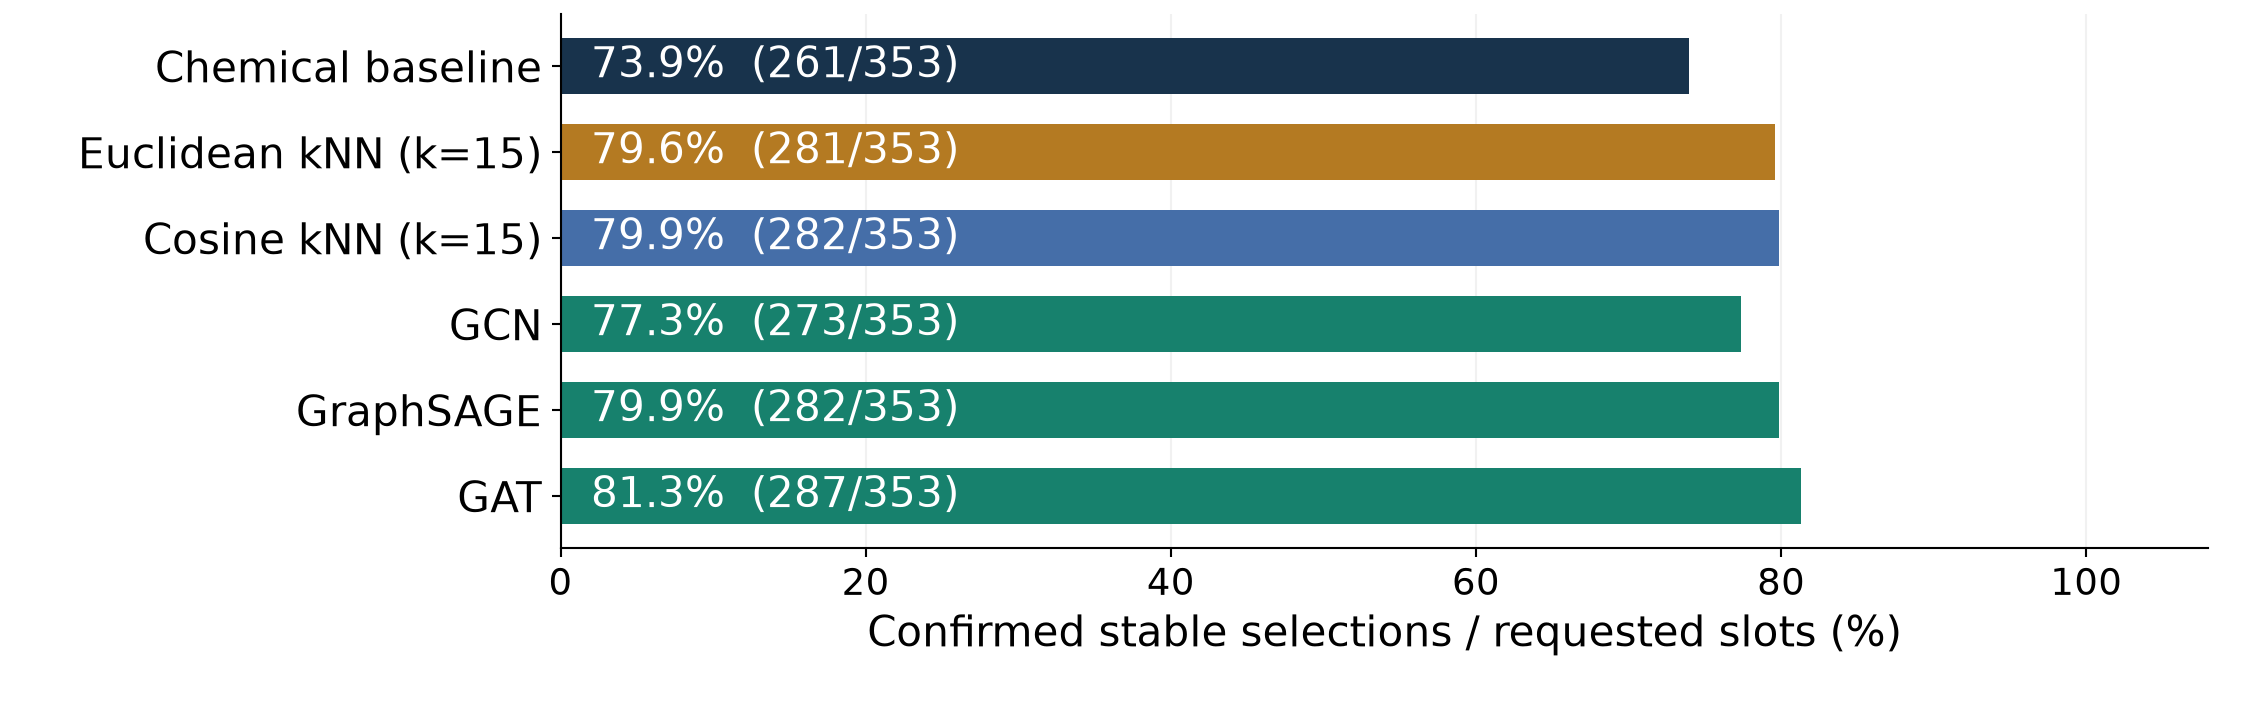

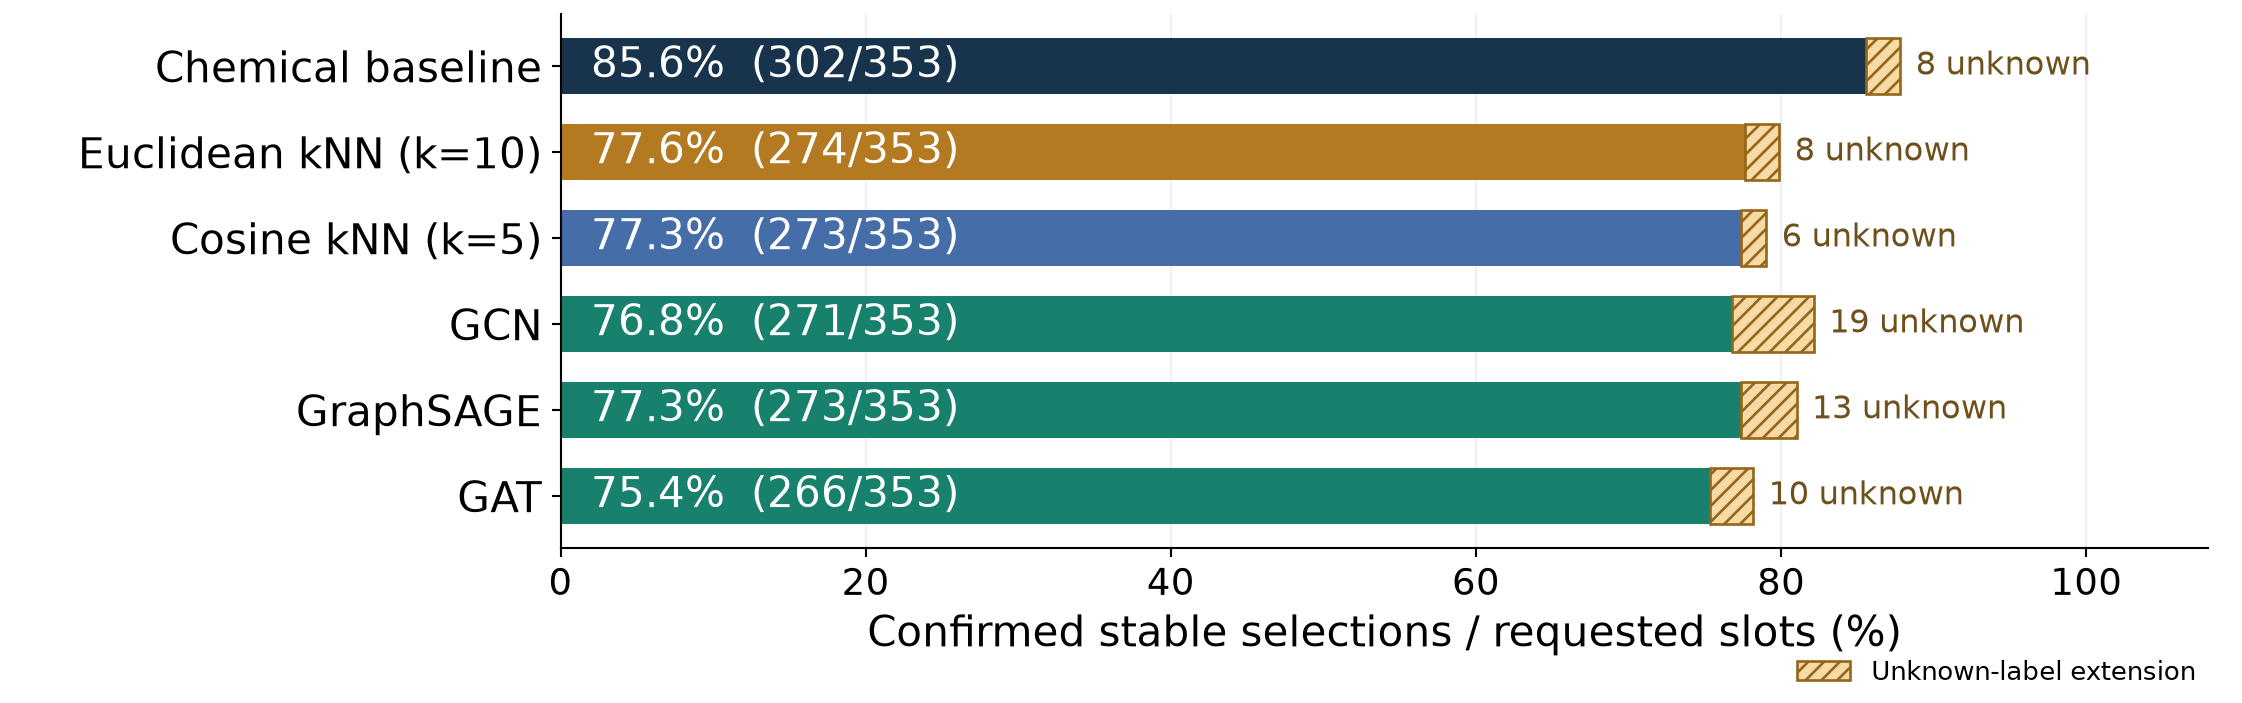

In [15]:
from evaluation.presentation_results import export_presentation_results
from IPython.display import display, Image
reporting_runs = export_presentation_results(analysis_config)
display(reporting_runs[['proxy', 'category', 'method', 'stable_count', 'unknown_count', 'budget', 'yield_lower']])
for proxy in ('megnet', 'chgnet'):
    display(Image(filename=str(ROOT / 'docs/assets' / f'{proxy}_heldout_1pct_best_runs.png'), width=1100))


## 9. LaTeX figure document and historical eSEN appendix

The report contains important new figures plus an appendix of previous eSEN
chemical and kNN results, retaining the original folders 20-29 and 1/5/10% budgets.
Main methodology and narrative will be supplied by the authors. Historical data
are not pooled with this evaluation. The next cell copies verified new figures
into the report assets; it never fabricates figures if the returned analysis is absent.


In [16]:
import shutil
from evaluation.reporting import historical_appendix
historical_appendix()
report_assets = ROOT / 'data/eval/report/assets'
for figure in (returned / 'figures').glob('*.pdf'):
    shutil.copy2(figure, report_assets / figure.name)
print('LaTeX source: data/eval/report/report.tex; compile as described in README.')


LaTeX source: data/eval/report/report.tex; compile as described in README.
